# Flow through sand: permeability from a Stokes solve

Water seeping through sand follows Darcy's law: the flow is proportional to the pressure drop, with the permeability
k as the factor, and k depends only on the geometry of the pores. The example is a sample of 1 × 1 with random discs
as grains: the water fills the space between them, netgen meshes it, and an NGSolve Stokes solve gives the flow. k
against the porosity follows the shape of the Kozeny-Carman law. Lengths are in mm.

![Water seeping through the pores of a random grain packing](../_static/gallery/flow-through-sand.png){.result}

In [1]:
import math
import random
import matplotlib.pyplot as plt
import numpy as np
import ngsolve as ngs
from ngsolve_webgpu.jupyter import Draw
import planex as px

In [2]:
from docs_figures import Row

## A packing

Grains of radius 0.02 to 0.06 are placed at random in a 1 × 1 sample, each at least 0.01 from the others and from
the walls, until the target number is reached or the space is used up. The sample is one sketch: the square with the
names that the flow needs on its sides, and the grains as holes in it (Figure 1).

In [3]:
def packing(count, seed=1, gap=0.01):
    rng = random.Random(seed)
    grains = []
    for attempt in range(200000):
        if len(grains) == count:
            break
        r = rng.uniform(0.02, 0.06)
        x, y = rng.uniform(r + gap, 1 - r - gap), rng.uniform(r + gap, 1 - r - gap)
        if all(math.hypot(x - a, y - b) > r + c + gap for a, b, c in grains):
            grains.append((x, y, r))
    sample = px.QuickSketch().Line(1, name="bottom").Turn(90).Line(1, name="outlet").Turn(90).Line(1, name="top")
    sample.Turn(90).Line(1, name="inlet")
    for x, y, r in grains:
        sample.Circle(x, y, r, name="grain")
    return sample.Face(), len(grains)


pores, placed = packing(500)
print(placed, "grains, porosity", round(pores.mass, 4))

143 grains, porosity 0.5729


In [4]:
Row((pores, "The pores between the grains"), caption="A random packing of grains")

## Stokes flow

The pressure is 1 at the inlet and 0 at the outlet, the grains hold the water still, and the top and bottom let it
slide. NGSolve solves with Taylor-Hood elements in one direct solve. The flow in must equal the flow out, and Darcy's
law gives k = μ q L / Δp from the flow per width q. The picture shows the velocity in the pores.

In [5]:
def flow(pores, mu=1.0, drop=1.0):
    mesh = ngs.Mesh(px.OCCGeometry(pores).GenerateMesh(maxh=0.03))
    mesh.Curve(3)
    V = ngs.VectorH1(mesh, order=2, dirichletx="grain", dirichlety="grain|top|bottom")
    Q = ngs.H1(mesh, order=1)
    X = V * Q
    (u, p), (v, q) = X.TnT()
    n = ngs.specialcf.normal(2)
    stokes = mu * ngs.InnerProduct(ngs.grad(u), ngs.grad(v)) - p * ngs.div(v) - q * ngs.div(u)
    a = ngs.BilinearForm(stokes * ngs.dx).Assemble()
    f = ngs.LinearForm(-drop * (v * n) * ngs.ds("inlet")).Assemble()
    state = ngs.GridFunction(X)
    state.vec.data = a.mat.Inverse(X.FreeDofs(), inverse="umfpack") * f.vec
    velocity = state.components[0]
    q_in = ngs.Integrate(velocity[0], mesh, ngs.BND, definedon=mesh.Boundaries("inlet"))
    q_out = ngs.Integrate(velocity[0], mesh, ngs.BND, definedon=mesh.Boundaries("outlet"))
    return mesh, velocity, q_in, q_out, mu * q_out * 1.0 / drop


mesh, velocity, q_in, q_out, k = flow(pores)
print(mesh.ne, "elements, flow in", q_in, "out", q_out)
print("permeability", f"{k:.3e}", "mm²")
Draw(velocity, mesh)

4297 elements, flow in 2.544452598968264e-05 out 2.5444525989682652e-05
permeability 2.544e-05 mm²


## Permeability against porosity

The packings range from loose to dense. Kozeny and Carman relate the permeability to the porosity φ and the grain
size d as k = d² φ³ / (C (1 − φ)²). The constant C differs for discs and spheres, so it is fitted here, and the shape
of the law is the test. The grains average a diameter `d` of 0.08, and C is fitted in the mean of the logarithms.

In [6]:
porosity, permeability = [], []
for count in (30, 60, 90, 120, 500):
    sample, placed = packing(count, seed=count)
    mesh, velocity, q_in, q_out, k = flow(sample)
    porosity.append(sample.mass)
    permeability.append(k)
    print(placed, "grains: porosity", round(sample.mass, 3), "permeability", f"{k:.3e}", "mm², flow balance",
          f"{abs(q_in - q_out) / q_out:.1e}")
d = 0.08
shape = np.array([d**2 * f**3 / (1 - f) ** 2 for f in porosity])
C = float(np.exp(np.mean(np.log(shape / np.array(permeability)))))
print("C", round(C))

30 grains: porosity 0.842 permeability 7.894e-04 mm², flow balance 2.7e-16


60 grains: porosity 0.751 permeability 2.702e-04 mm², flow balance 2.0e-16


90 grains: porosity 0.652 permeability 6.978e-05 mm², flow balance 0.0e+00


120 grains: porosity 0.655 permeability 5.444e-05 mm², flow balance 2.5e-16


138 grains: porosity 0.555 permeability 2.498e-05 mm², flow balance 5.4e-16
C 210


The permeabilities of the five packings against the fitted law:

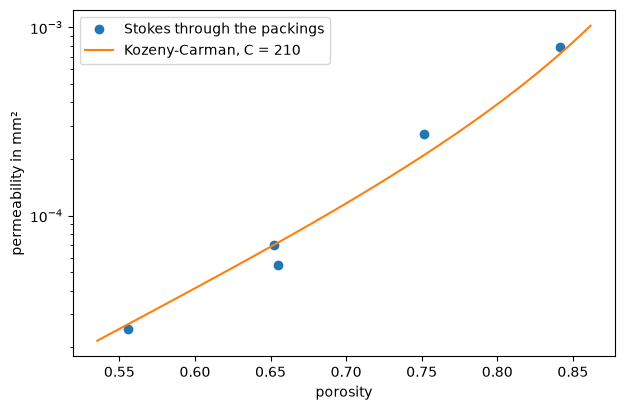

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(porosity, permeability, "o", label="Stokes through the packings")
grid = np.linspace(min(porosity) - 0.02, max(porosity) + 0.02, 50)
ax.semilogy(grid, d**2 * grid**3 / (C * (1 - grid) ** 2), label=f"Kozeny-Carman, C = {C:.0f}")
ax.set_xlabel("porosity")
ax.set_ylabel("permeability in mm²")
ax.legend()
plt.show()

In [8]:
from ngsolve.webgui import Draw as WebguiDraw
import sys
sys.path.insert(0, "..")
from gallery import save_scene, save_figure, save_animation, HIDDEN
from gallery import CLEAN
speed = ngs.GridFunction(ngs.H1(mesh, order=1))
speed.Set(ngs.Norm(velocity))
save_scene(WebguiDraw(ngs.Norm(velocity), mesh, min=0, max=0.5 * max(speed.vec),
                      settings={**CLEAN, "Colormap": {"ncolors": 32}}, show=False), "flow-through-sand")